# Solve Max-Cut as a QUBO with D-Wave Ocean

This notebook formulates a small weighted Max-Cut problem as a QUBO, solves it with local classical simulated annealing, visualizes the result, and verifies it by exhaustive search. No D-Wave API token is needed.

## 1. Install dependencies

Run the next cell once if the packages are not installed.

In [2]:
%pip install -q "dwave-ocean-sdk>=9.0,<10" networkx matplotlib

Note: you may need to restart the kernel to use updated packages.


## 2. Define and draw a graph

The graph is a square A-B-C-D-A with diagonal A-C. Every edge has weight 1.

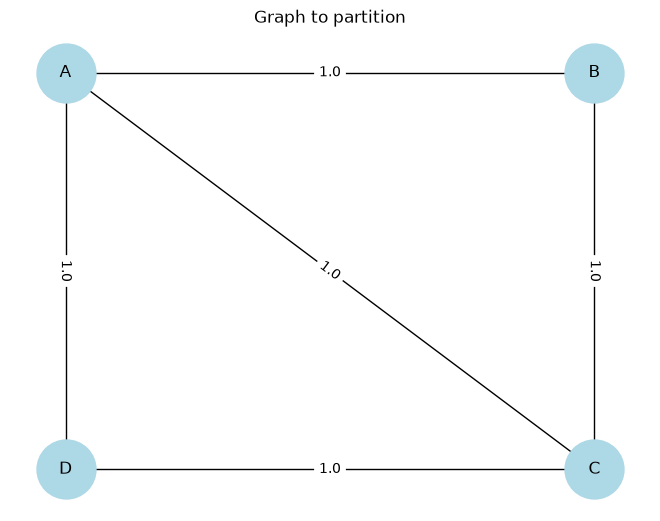

In [3]:
import networkx as nx
import matplotlib.pyplot as plt
import dimod
from dwave.samplers import SimulatedAnnealingSampler

edges = [
    ("A", "B", 1.0),
    ("B", "C", 1.0),
    ("C", "D", 1.0),
    ("D", "A", 1.0),
    ("A", "C", 1.0),
]

graph = nx.Graph()
graph.add_weighted_edges_from(edges)
positions = {"A": (-1, 1), "B": (1, 1), "C": (1, -1), "D": (-1, -1)}

nx.draw(graph, positions, with_labels=True, node_color="lightblue", node_size=1800)
nx.draw_networkx_edge_labels(graph, positions, edge_labels=nx.get_edge_attributes(graph, "weight"))
plt.title("Graph to partition")
plt.show()

## 3. Formulate the QUBO

Give every vertex a binary variable $x_v$. Zero means partition 0 and one means partition 1. For an edge $(u,v)$ with weight $w$, the cut contribution is

$$w(x_u+x_v-2x_ux_v).$$

It equals $w$ when the endpoints differ and zero when they are together. Ocean minimizes energy, so negate it:

$$\min \sum_{(u,v)}[-wx_u-wx_v+2wx_ux_v].$$

For each edge, add $-w$ to the two diagonal coefficients and $+2w$ to the quadratic coefficient. Every assignment is a valid partition, so no penalty term is necessary.

In [4]:
from collections import defaultdict

Q = defaultdict(float)
for u, v, weight in edges:
    Q[(u, u)] -= weight
    Q[(v, v)] -= weight
    Q[(u, v)] += 2.0 * weight

Q = dict(Q)
Q

{('A', 'A'): -3.0,
 ('B', 'B'): -2.0,
 ('A', 'B'): 2.0,
 ('C', 'C'): -3.0,
 ('B', 'C'): 2.0,
 ('D', 'D'): -2.0,
 ('C', 'D'): 2.0,
 ('D', 'A'): 2.0,
 ('A', 'C'): 2.0}

## 4. Build and solve the binary quadratic model

One hundred reads means 100 independent annealing attempts. The fixed seed makes the example reproducible.

In [5]:
bqm = dimod.BinaryQuadraticModel.from_qubo(Q)
sampler = SimulatedAnnealingSampler()
sampleset = sampler.sample(
    bqm, num_reads=100, num_sweeps=1000, seed=42
).aggregate()

sampleset

SampleSet(rec.array([([0, 1, 0, 1], -4., 48), ([1, 0, 1, 0], -4., 52)],
          dtype=[('sample', 'i1', (4,)), ('energy', '<f8'), ('num_occurrences', '<i8')]), Variables(['A', 'B', 'C', 'D']), {'beta_range': [np.float64(0.23104906018664842), np.float64(5.991464547107982)], 'beta_schedule_type': 'geometric', 'timing': {'preprocessing_ns': 6279000, 'sampling_ns': 5242750, 'postprocessing_ns': 185125}}, 'BINARY')

## 5. Decode the best result

Because the cut objective was negated, cut weight equals negative QUBO energy.

In [7]:
best = sampleset.first
solution = {vertex: int(side) for vertex, side in best.sample.items()}
partition_0 = sorted(v for v, side in solution.items() if side == 0)
partition_1 = sorted(v for v, side in solution.items() if side == 1)
cut_edges = [(u, v, w) for u, v, w in edges if solution[u] != solution[v]]
cut_weight = sum(w for _, _, w in cut_edges)

print("Binary assignment:", solution)
print("Partition 0:", partition_0)
print("Partition 1:", partition_1)
print("Cut edges:", cut_edges)
print("Cut weight:", cut_weight)
print("QUBO energy:", best.energy)
assert abs(best.energy + cut_weight) < 1e-9

Binary assignment: {'A': 0, 'B': 1, 'C': 0, 'D': 1}
Partition 0: ['A', 'C']
Partition 1: ['B', 'D']
Cut edges: [('A', 'B', 1.0), ('B', 'C', 1.0), ('C', 'D', 1.0), ('D', 'A', 1.0)]
Cut weight: 4.0
QUBO energy: -4.0


## 6. Visualize the maximum cut

Blue and orange are the partitions. Red edges cross the cut.

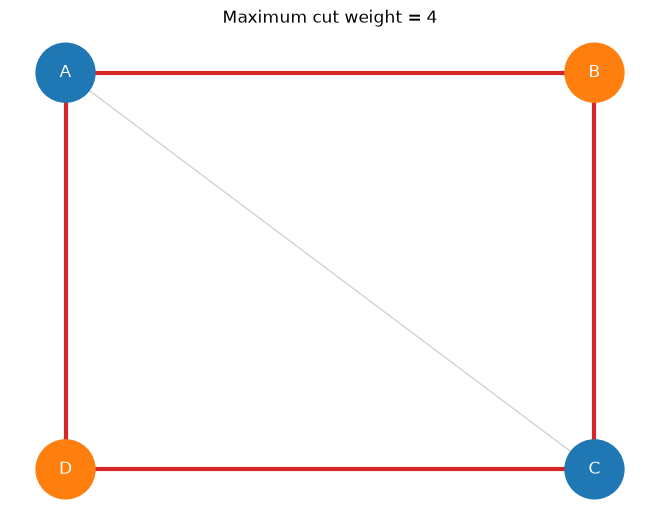

In [8]:
node_colors = ["tab:blue" if solution[v] == 0 else "tab:orange" for v in graph.nodes]
edge_colors = ["tab:red" if solution[u] != solution[v] else "lightgray" for u, v in graph.edges]
edge_widths = [3 if solution[u] != solution[v] else 1 for u, v in graph.edges]

nx.draw(
    graph, positions, with_labels=True, node_color=node_colors,
    edge_color=edge_colors, width=edge_widths, node_size=1800, font_color="white"
)
plt.title(f"Maximum cut weight = {cut_weight:g}")
plt.show()

## 7. Verify by exhaustive search

With four variables, there are only $2^4=16$ assignments. ExactSolver checks all of them and is useful for validating small problems.

In [9]:
exact_sampleset = dimod.ExactSolver().sample(bqm)
exact_solution = {v: int(side) for v, side in exact_sampleset.first.sample.items()}
exact_cut_weight = -exact_sampleset.first.energy

print("One exact optimum:", exact_solution)
print("Exact maximum cut weight:", exact_cut_weight)
assert abs(cut_weight - exact_cut_weight) < 1e-9
print("Verification passed: simulated annealing found a maximum cut.")

One exact optimum: {'A': 1, 'B': 0, 'C': 1, 'D': 0}
Exact maximum cut weight: 4.0
Verification passed: simulated annealing found a maximum cut.


## 8. Next experiment

Change the edges list in section 2 and rerun the cells below it. Each tuple contains two vertices and a nonnegative weight. For larger graphs, try increasing the number of reads or sweeps.

**Important:** simulated annealing is a classical heuristic. It uses Ocean's sampler interface but does not simulate the internal quantum physics of a D-Wave QPU.